# Adaboost Hyperparameters

- Mainly 4 hyperparameters: 
    1. base_estimator: The weak learner model to be used. Default is DecisionTreeClassifier(max_depth=1).
    2. n_estimators: The number of weak learners to be used. Default is 50.
    3. learning_rate: The weight applied to each weak learner. Default is 1.0.
    4. algorithm: The algorithm to be used. Default is 'SAMME.R'. Other option is 'SAMME'.


## AdaBoost - Base Estimators

- AdaBoost can use different ML algorithms as base estimators.
- The most commonly used estimator is a **Decision Stump** (`max_depth=1`).

### Requirements
- The base estimator's `fit()` method must support `sample_weight`.
- AdaBoost internally calculates and updates sample weights; we don't pass them manually.
- Weak learners are preferred because AdaBoost combines them to build a strong learner.

### Compatibility
- Decision Tree: Yes
- Logistic Regression: Yes
- SVM (SVC): Yes
- Random Forest: Yes (technically, but not ideal)
- KNN: No (standard implementation)
- Naive Bayes: Generally no (standard implementation)

### Why is KNN not supported?
- AdaBoost passes updated sample weights to the base estimator during training.
- KNN's `fit()` method does not accept `sample_weight`.
- Hence, standard KNN cannot be directly used as an AdaBoost base estimator.

**Remember:** The base estimator must support `sample_weight` in its `fit()` method. Decision Stumps are the most common choice.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.plotting import plot_decision_regions
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_circles

In [2]:
np.random.seed(42)
X, y = make_circles(n_samples=500, factor=0.1, noise=0.35, random_state=42)
#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

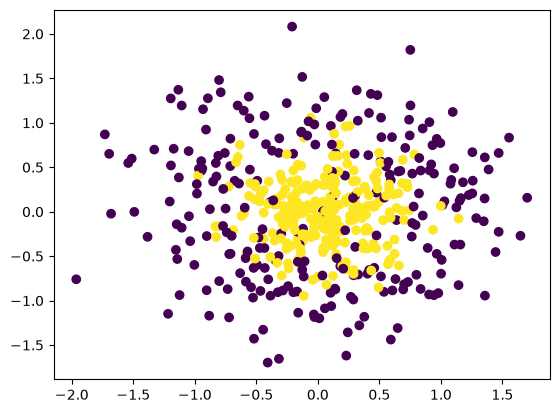

In [3]:
plt.scatter(X[:,0],X[:,1],c=y)

In [4]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import cross_val_score

abc = AdaBoostClassifier()

np.mean(cross_val_score(abc,X,y,scoring='accuracy',cv=10))

np.float64(0.812)

In [5]:
abc.fit(X,y)

,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",50
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",None


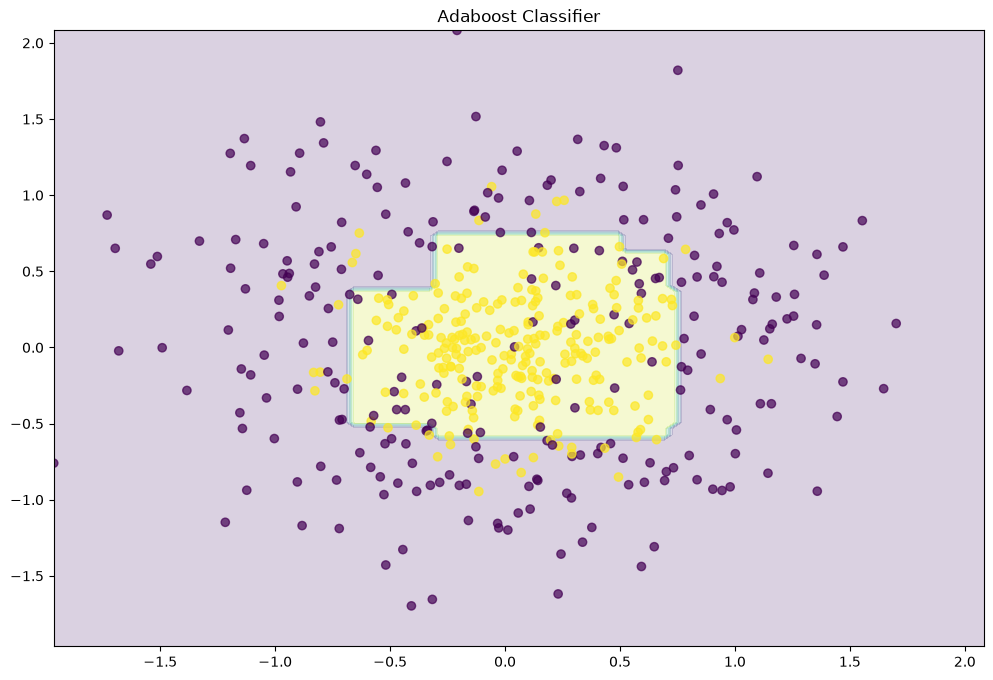

In [6]:
def plot_decision_boundary(clf):
    plt.figure(figsize=(12, 8))
    x_range = np.linspace(X.min(), X.max(), 100)
    xx1, xx2 = np.meshgrid(x_range, x_range)
    y_hat = clf.predict(np.c_[xx1.ravel(), xx2.ravel()])
    y_hat = y_hat.reshape(xx1.shape)
    plt.contourf(xx1, xx2, y_hat, alpha=0.2)
    plt.scatter(X[:,0], X[:,1], c=y, cmap='viridis', alpha=.7)
    plt.title("Adaboost Classifier")
    plt.show()
    
plot_decision_boundary(abc)

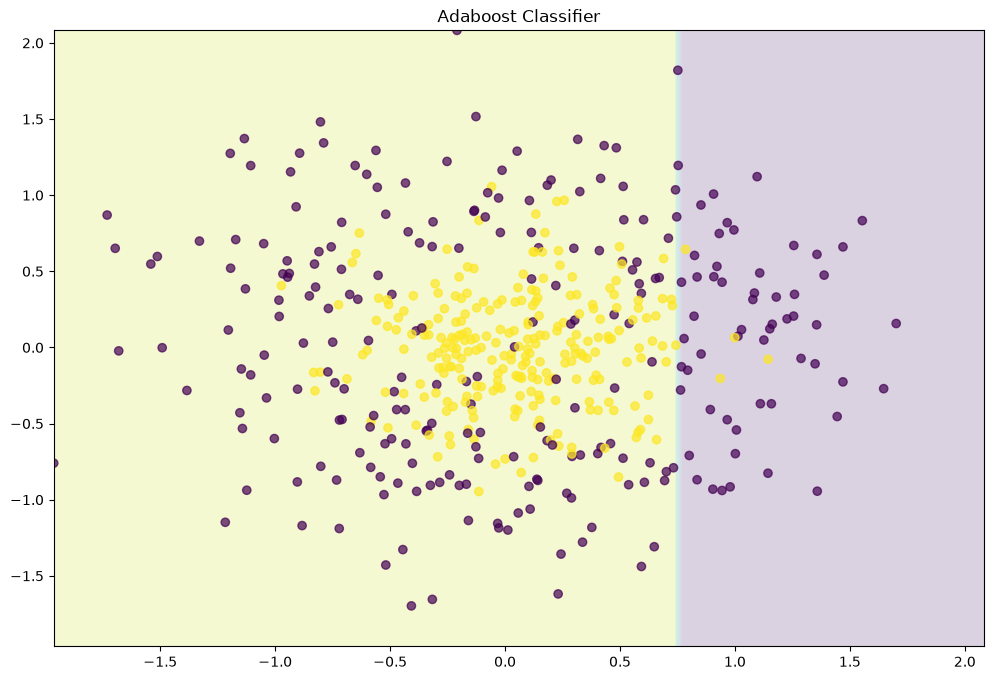

In [11]:
abc = AdaBoostClassifier(n_estimators=1) #underfitting (only 1 desion stump)
abc.fit(X,y)
plot_decision_boundary(abc)

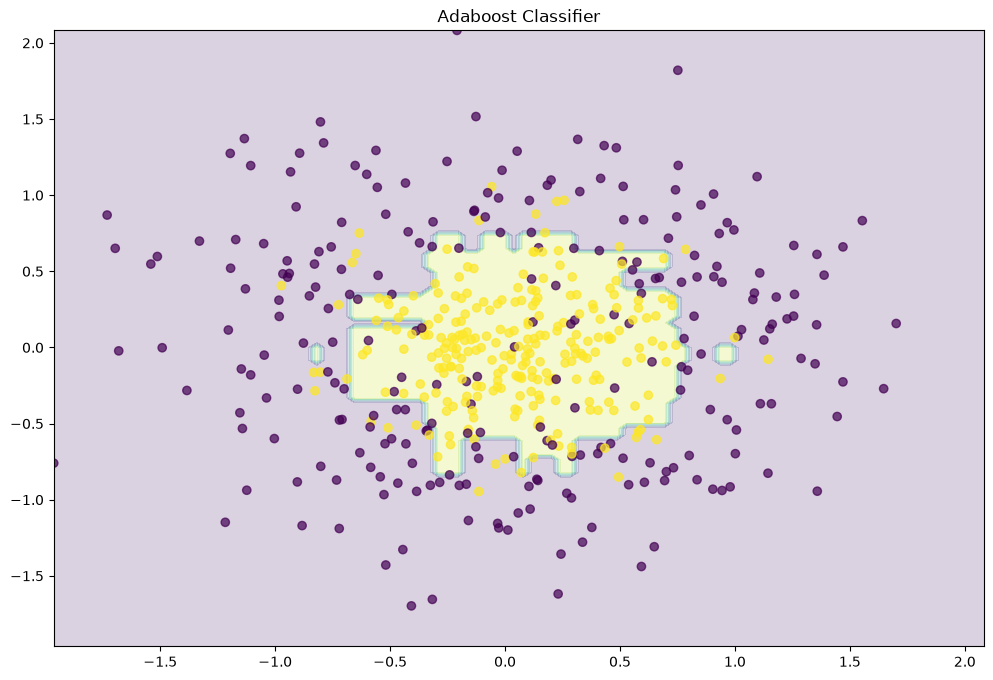

In [ ]:
abc = AdaBoostClassifier(n_estimators=2500) # over fitting (too many decision stumps)
abc.fit(X,y)
plot_decision_boundary(abc)

# Learning Rate Hyperparameter

- It get multiplied to $alpha$ value of each weak learner. So while weight updating, the weight of each weak learner will be multiplied by learning rate.

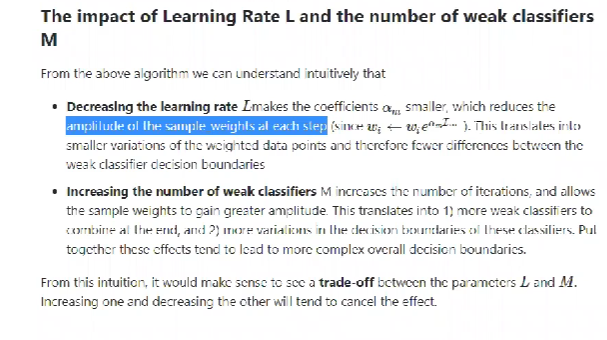


- So for high `n_estimators` you can use low `learning_rate`. So that the model will not overfit.


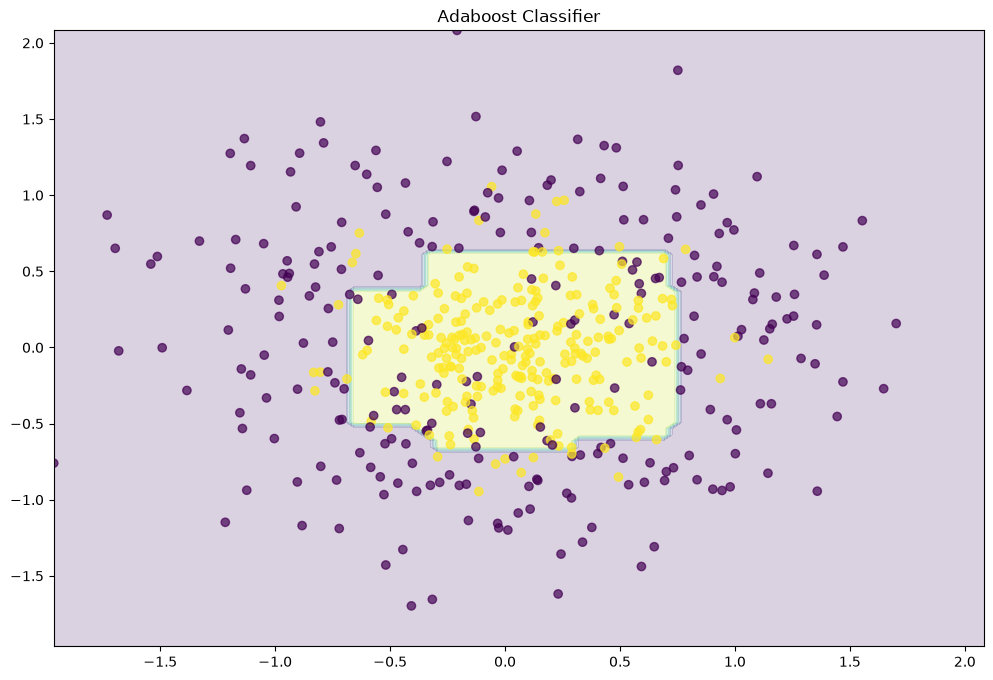

In [15]:
abc = AdaBoostClassifier(n_estimators=2500, learning_rate=0.1)
abc.fit(X,y)
plot_decision_boundary(abc)

In [17]:
from sklearn.model_selection import GridSearchCV

grid = dict()
grid['n_estimators'] = [10, 50, 100, 500]
grid['learning_rate'] = [0.0001, 0.001, 0.01, 0.1, 1.0]
# grid['algorithm'] = ['SAMME', 'SAMME.R']


grid_search = GridSearchCV(estimator=AdaBoostClassifier(), param_grid=grid, n_jobs=-1, cv=10, scoring='accuracy')
# execute the grid search
grid_result = grid_search.fit(X, y)
# summarize the best score and configuration
print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))

Best: 0.832000 using {'learning_rate': 0.1, 'n_estimators': 500}


In [ ]:
# Link
https://stats.stackexchange.com/questions/82323/shrinkage-parameter-in-adaboost